# 02 — Analyse exploratoire des donnees (EDA) — version 3


In [2]:
from pathlib import Path
import warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
RNG = np.random.default_rng(42)

_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents]
                     if (p/"data"/"processed"/"era5_algeria_masked_2x2_v2.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("era5_algeria_masked_2x2_v2.nc introuvable : exécutez d'abord le notebook 01.")
ds = xr.open_dataset(PROJECT_ROOT/"data"/"processed"/"era5_algeria_masked_2x2_v2.nc")

step = float(abs(ds.latitude.diff("latitude")).mean())
print("Dimensions :", dict(ds.sizes))

Dimensions : {'valid_time': 141, 'latitude': 95, 'longitude': 105}


## 0. Conversion des unites et construction des tableaux d'analyse

In [3]:
BASE = ["d2m","t2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]
ALL  = BASE + ["wind10_speed"]
LABELS = {"d2m":"Point de rosee 2 m (°C)","t2m":"Temperature 2 m (°C)","slhf":"Flux chaleur latente (W/m²)",
          "ssr":"Rayonnement solaire net (W/m²)","str":"Rayonnement thermique net (W/m²)","sshf":"Flux chaleur sensible (W/m²)",
          "ro":"Ruissellement (mm/j)","e":"Evaporation (mm/j)","u10":"Vent u10 (m/s)","v10":"Vent v10 (m/s)",
          "sp":"Pression surface (hPa)","tp":"Precipitation (mm/j)","wind10_speed":"Vitesse du vent 10 m (m/s)"}
UNITS = {"d2m":"°C","t2m":"°C","slhf":"W/m²","ssr":"W/m²","str":"W/m²","sshf":"W/m²",
         "ro":"mm/j","e":"mm/j","tp":"mm/j","u10":"m/s","v10":"m/s","wind10_speed":"m/s","sp":"hPa"}

conv = xr.Dataset(coords=ds.coords)
for v in ["d2m","t2m"]:               conv[v] = ds[v] - 273.15
for v in ["slhf","ssr","str","sshf"]: conv[v] = ds[v] / 86400.0
for v in ["ro","e","tp"]:             conv[v] = ds[v] * 1000.0
conv["sp"] = ds["sp"] / 100.0
conv["u10"], conv["v10"] = ds["u10"], ds["v10"]
conv["wind10_speed"] = np.hypot(ds["u10"], ds["v10"])

# (a) serie regionale : moyenne pondérée par cos(lat), cellules NaN ignorees
w = np.cos(np.deg2rad(conv.latitude))
regional = pd.DataFrame({v: conv[v].weighted(w).mean(("latitude","longitude")).to_series() for v in ALL})
regional.index = pd.to_datetime(regional.index)
months_ok = (regional.index.to_period("M").to_series().diff().dropna().apply(lambda x: x.n) == 1).all()
print("Serie regionale :", regional.shape, "|", regional.index.min().date(), "→", regional.index.max().date(),
      "| mois consécutifs :", months_ok)

# (b) tableau échantillons : 1 ligne = (cellule, mois), uniquement les cellules du domaine Algérie
valid_cells = conv["t2m"].notnull().any("valid_time")
vm = valid_cells.values
T, N = conv.sizes["valid_time"], int(vm.sum())
ilat, ilon = np.where(vm)
df = pd.DataFrame({v: conv[v].values[:, vm].reshape(-1) for v in ALL})
df["time"] = np.repeat(conv.valid_time.values, N)
df["cell"] = np.tile(np.arange(N), T)
df["lat"]  = np.tile(conv.latitude.values[ilat], T)
df["lon"]  = np.tile(conv.longitude.values[ilon], T)
df["year"] = pd.DatetimeIndex(df["time"]).year
df["month"] = pd.DatetimeIndex(df["time"]).month

# cible exploratoire : classe de t2m du mois suivant, 3 intervalles de MÊME LARGEUR (equal-width, cours 04)
A = conv["t2m"].values[:, vm]
df["t2m_next"] = np.vstack([A[1:], np.full((1, N), np.nan)]).reshape(-1)
lo, hi = np.nanmin(df["t2m_next"]), np.nanmax(df["t2m_next"])
EDGES = np.linspace(lo, hi, 4)
df["classe"] = pd.cut(df["t2m_next"], bins=EDGES, labels=["Froid","Modere","Chaud"], include_lowest=True)
df["saison"] = df["month"].map({12:"Hiver",1:"Hiver",2:"Hiver",3:"Printemps",4:"Printemps",5:"Printemps",
                                6:"Été",7:"Été",8:"Été",9:"Automne",10:"Automne",11:"Automne"})
print(f"Tableau échantillons : {df.shape[0]:,} lignes = {N:,} cellules × {T} mois")
print("Seuils de classes (°C), largeur égale :", np.round(EDGES, 2))
display(df["classe"].value_counts(dropna=False).to_frame("effectif"))
SAMPLE = df.sample(60_000, random_state=42)   # échantillon pour les graphiques lourds uniquement

c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\arrays\datetimelike.py:1329: RuntimeWarning: overflow encountered in scalar multiply
  new_data = np.array([self.freq.base * x for x in new_i8_data])


Serie regionale : (141, 13) | 2015-01-01 → 2026-09-01 | mois consécutifs : True
Tableau échantillons : 764,784 lignes = 5,424 cellules × 141 mois
Seuils de classes (°C), largeur égale : [ 0.91 14.33 27.74 41.16]


,effectif
classe,
Modere,327329
Chaud,302584
Froid,129447
NaN,5424


## 1. Qualité des données (Cours 03 « Missing value / Unique values » + Cours 04 « Data quality »)

### 1.1 Valeurs manquantes

Cellules de la grille : 9975 | dans le domaine (≥1 valeur) : 5424 | hors domaine (masque) : 4551
Cellules du domaine avec des mois manquants : 0


,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp,wind10_speed
NaN (domaine),0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0
% NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0
valeurs = 0,0.0,0.0,0.0,0.0,0.0,0.0,148681.000,0.0,1.0,1.0,0.0,0.0,0.0
% zéros,0.0,0.0,0.0,0.0,0.0,0.0,19.441,0.0,0.0,0.0,0.0,0.0,0.0


Même motif de NaN pour toutes les variables ?  True


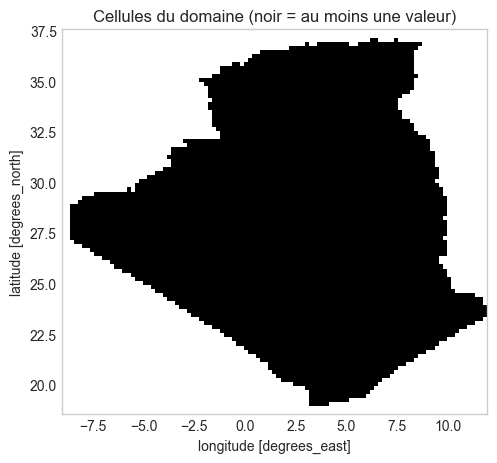

In [4]:
n_total = conv.sizes["latitude"] * conv.sizes["longitude"]
print(f"Cellules de la grille : {n_total} | dans le domaine (≥1 valeur) : {N} | hors domaine (masque) : {n_total-N}")
partial = conv["t2m"].isnull().any("valid_time") & valid_cells
print("Cellules du domaine avec des mois manquants :", int(partial.sum()))

miss = pd.DataFrame({
    "NaN (domaine)": df[ALL].isna().sum(),
    "% NaN": (df[ALL].isna().mean()*100).round(3),
    "valeurs = 0": (df[ALL] == 0).sum(),
    "% zéros": ((df[ALL] == 0).mean()*100).round(3)})
display(miss.T)
print("Même motif de NaN pour toutes les variables ? ",
      bool((df[ALL].isna().nunique(axis=1) == 1).all()))

fig, ax = plt.subplots(figsize=(6.5, 5))
valid_cells.astype(int).plot.pcolormesh(ax=ax, x="longitude", y="latitude", cmap="Greys", add_colorbar=False)
ax.set_title("Cellules du domaine (noir = au moins une valeur)"); ax.set_aspect("equal"); plt.show()

**Frontière nord.** Dans le notebook 01 la réduction 2×2 utilise `coarsen().mean()` qui **ignore les NaN** : une cellule réduite n'est NaN que si ses 4 sous-cellules le sont. Les trous de la frontière nord (cellules dans le polygone mais sans donnée ERA5-Land, ex. mer) sont donc masqués après réduction. La cellule suivante les recompte sur la grille brute si elle est disponible.

Grille brute — cellules dans le polygone : 21257
  • sans aucune valeur t2m sur toute la période (trous frontière) : 12
  • avec des mois manquants seulement : 0


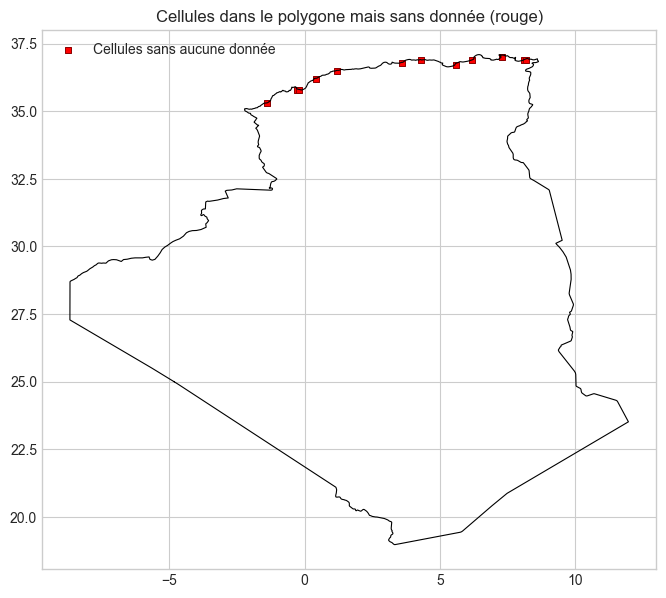

In [5]:

try:
    import sys
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
    from climate_utils import make_algeria_mask

    ds_raw = xr.open_dataset(PROJECT_ROOT / "data" / "raw" / "era5_algeria_raw.nc")
    mask, algeria = make_algeria_mask(ds_raw, PROJECT_ROOT)

    t_in = ds_raw["t2m"].where(mask)

    never = mask & t_in.isnull().all("valid_time")
    some = mask & t_in.isnull().any("valid_time") & ~t_in.isnull().all("valid_time")

    print("Grille brute — cellules dans le polygone :", int(mask.sum()))
    print("  • sans aucune valeur t2m sur toute la période (trous frontière) :", int(never.sum()))
    print("  • avec des mois manquants seulement :", int(some.sum()))

    fig, ax = plt.subplots(figsize=(9, 7))

    # Afficher les cellules sans aucune donnée
    lat, lon = np.where(never.values)

    ax.scatter(
        never.longitude.values[lon],
        never.latitude.values[lat],
        color="red",
        s=25,
        marker="s",
        edgecolors="darkred",
        linewidths=0.7,
        zorder=5,
        label="Cellules sans aucune donnée"
    )

    # Tracer les frontières de l'Algérie
    for g in getattr(algeria, "geoms", [algeria]):
        x, y = g.exterior.xy
        ax.plot(x, y, "k", lw=0.8, zorder=6)

    ax.set_title("Cellules dans le polygone mais sans donnée (rouge)")
    ax.set_aspect("equal")
    ax.legend()
    plt.show()

except Exception as err:
    print("Contrôle sur la grille brute non exécuté :", type(err).__name__, "-", err)


### 1.2 Valeurs uniques (Cours 03)
Nombre de valeurs distinctes par variable : une variable à très peu de valeurs uniques porte peu d'information ; on vérifie aussi qu'il n'y a aucun doublon de clé (cellule, mois).

In [6]:
uniq = pd.DataFrame({"valeurs uniques": df[ALL].nunique(),
                     "% uniques": (df[ALL].nunique()/len(df)*100).round(2)})
display(uniq.T)
print("Doublons de la clé (cellule, mois) :", int(df.duplicated(["cell","time"]).sum()))

,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp,wind10_speed
valeurs uniques,111153.00,143383.00,559439.00,734307.00,723356.00,743414.00,31944.00,540309.00,665481.00,635105.00,218448.00,599605.0,754529.00
% uniques,14.53,18.75,73.15,96.01,94.58,97.21,4.18,70.65,87.02,83.04,28.56,78.4,98.66


Doublons de la clé (cellule, mois) : 0


### 1.3 Variabilité / variance faible (Cours 04 « What features to eliminate » : seuil **variance < 0.01**)
Le seuil 0.01 **dépend des unités** : la variance du ruissellement vaut ~10⁻³ en mm/j mais ~10⁻⁹ en m/j (unité du fichier), où `e` et `tp` passeraient aussi sous le seuil. On ajoute donc deux mesures indépendantes des unités :
- la **variance après normalisation Min-Max** (cours 05), à laquelle on applique le seuil 0.01 ;
- la **part de variance temporelle** (variance dans le temps de chaque cellule / variance totale), propre à un dataset spatio-temporel.

In [7]:
var_tab = pd.DataFrame({"unité": [UNITS[v] for v in ALL],
                        "variance (unités d'analyse)": df[ALL].var().values}, index=ALL)
mm = (df[ALL] - df[ALL].min()) / (df[ALL].max() - df[ALL].min())
var_tab["variance Min-Max"] = mm.var().values
var_tab["% variance temporelle"] = [100 * float(conv[v].var("valid_time").mean()) / df[v].var(ddof=0) for v in ALL]
var_tab["< 0.01 (unités)"] = var_tab["variance (unités d'analyse)"] < 0.01
var_tab["< 0.01 (Min-Max)"] = var_tab["variance Min-Max"] < 0.01
print(var_tab.to_string(float_format=lambda x: f"{x:.4g}"))
LOW_VAR_UNITS = var_tab.index[var_tab["< 0.01 (unités)"]].tolist()
LOW_VAR = var_tab.index[var_tab["< 0.01 (Min-Max)"]].tolist()
print("Variance < 0.01 en unités d'analyse :", LOW_VAR_UNITS)
print("Variance Min-Max < 0.01 :", LOW_VAR, "→ à réévaluer après traitement des queues lourdes (notebook 03)")
print("Variable quasi constante dans le temps (< 5 % de variance temporelle) :", var_tab.index[var_tab["% variance temporelle"] < 5].tolist())  #Est-ce que cette variable change dans le temps ou principalement selon la géographie ?

c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\xarray\core\nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\xarray\core\nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\xarray\core\nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\xarray\core\nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\xarray\core\nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.

             unité  variance (unités d'analyse)  variance Min-Max  % variance temporelle  < 0.01 (unités)  < 0.01 (Min-Max)
d2m             °C                         23.4           0.01453                  66.33            False             False
t2m             °C                        76.56           0.04727                   84.9            False             False
slhf          W/m²                        134.2          0.005722                  32.95            False              True
ssr           W/m²                         2410           0.03324                  89.06            False             False
str           W/m²                        909.2           0.04164                  80.74            False             False
sshf          W/m²                        499.3           0.01024                  79.84            False             False
ro            mm/j                     0.001444         4.016e-05                   66.5             True              True
e       

## 2. Analyse **univariée** (Cours 03)
Statistiques, asymétrie, histogrammes, boxplots, outliers (méthodes **Z-score** et **IQR** du cours), quantile plot, test de normalité.

In [8]:
desc = df[ALL].describe(percentiles=[.25,.5,.75]).T
desc["IQR"] = desc["75%"] - desc["25%"]
desc.insert(0, "unité", [UNITS[v] for v in ALL])
display(desc.drop(columns="count").round(3))

,unité,mean,std,min,25%,50%,75%,max,IQR
d2m,°C,1.545,4.837,-17.608,-1.740,1.324,4.581,22.523,6.322
t2m,°C,23.889,8.750,0.914,16.403,24.219,31.728,41.159,15.325
slhf,W/m²,-5.806,11.584,-153.195,-3.673,-2.108,-1.002,-0.046,2.671
ssr,W/m²,156.376,49.095,31.913,117.369,161.707,194.756,301.187,77.388
str,W/m²,-110.075,30.154,-172.637,-134.106,-114.803,-92.089,-24.867,42.016
sshf,W/m²,-39.275,22.346,-162.160,-53.843,-39.501,-21.300,58.698,32.543
ro,mm/j,0.004,0.038,0.000,0.000,0.000,0.000,5.997,0.000
e,mm/j,-0.201,0.400,-5.293,-0.127,-0.073,-0.035,-0.002,0.092
u10,m/s,-1.026,1.587,-6.709,-2.134,-0.995,0.059,7.470,2.194
v10,m/s,-0.514,1.045,-4.809,-1.160,-0.466,0.195,3.350,1.355


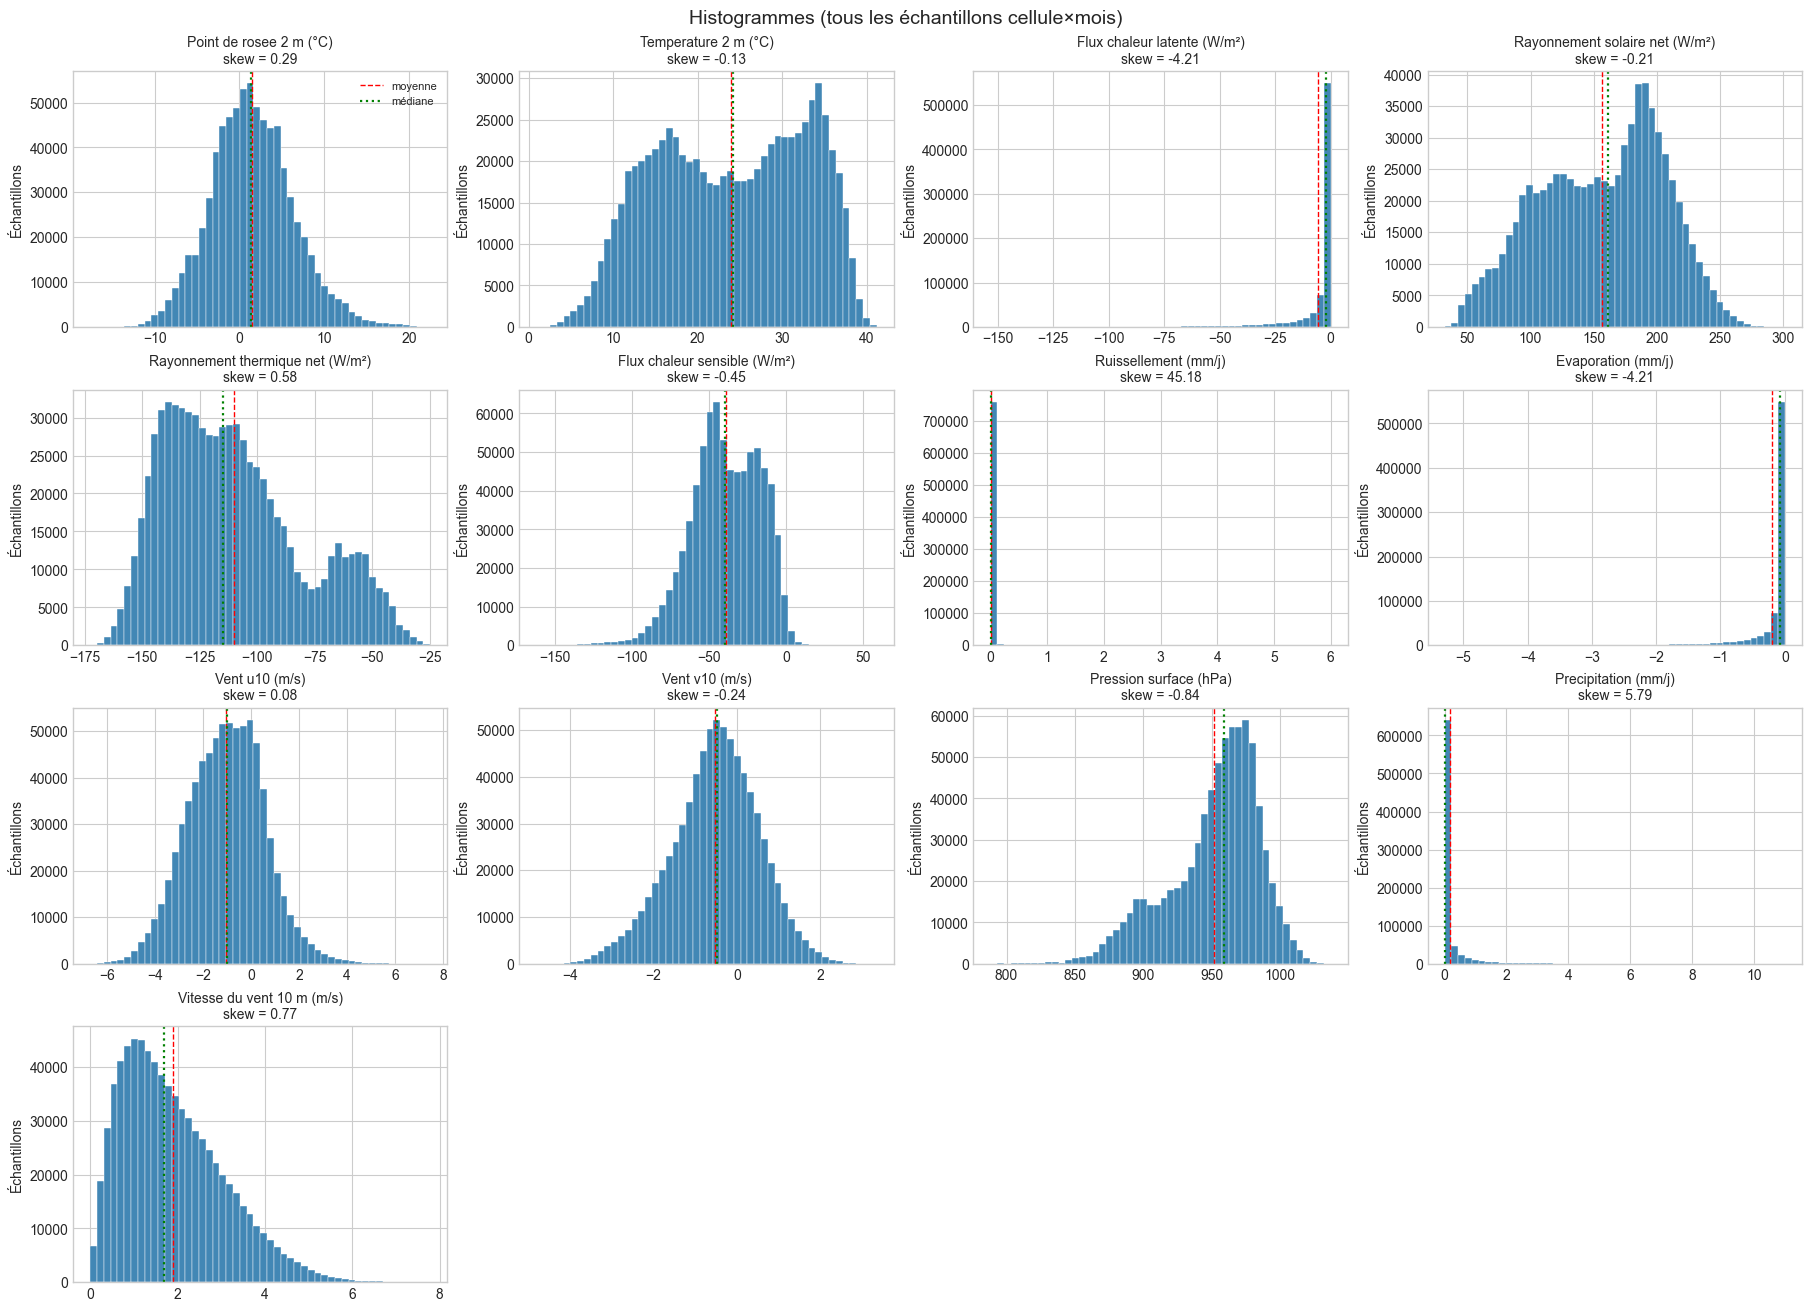

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(18, 13), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    ax.hist(df[v].dropna(), bins=50, color="#4287b5", edgecolor="white", linewidth=.3)
    ax.axvline(df[v].mean(), color="red", ls="--", lw=1, label="moyenne")
    ax.axvline(df[v].median(), color="green", ls=":", lw=1.6, label="médiane")
    ax.set_title(f"{LABELS[v]}\nskew = {stats.skew(df[v].dropna()):.2f}", fontsize=10); ax.set_ylabel("Échantillons")
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Histogrammes (tous les échantillons cellule×mois)", fontsize=14); plt.show()

La plupart du temps, une cellule géographique peut enregistrer peu ou pas de pluie. Mais certains mois, elle peut recevoir beaucoup de précipitations.

In [10]:
'''Le skewness mesure l'asymétrie de la distribution.
- Skew proche de 0 : distribution relativement symétrique.
- Skew positif : queue étendue vers les grandes valeurs (droite).
- Skew négatif : queue étendue vers les petites valeurs (gauche).
- Skew très éloigné de 0 : forte asymétrie.'''
def outlier_table(d, cols):
    rows = []
    for v in cols:
        x = d[v].dropna().values
        q1, q3 = np.percentile(x, [25, 75]); i = q3 - q1
        iqr_n = int(((x < q1-1.5*i) | (x > q3+1.5*i)).sum())
        z = (x - x.mean()) / x.std(ddof=1)
        z_n = int((np.abs(z) > 3).sum())
        rows.append({"variable": v, "outliers IQR (n)": iqr_n, "% IQR": 100*iqr_n/len(x),
                     "outliers Z>3 (n)": z_n, "% Z-score": 100*z_n/len(x), "skew": stats.skew(x)})
    return pd.DataFrame(rows).set_index("variable")

out_grid = outlier_table(df, ALL)
display(out_grid.round(2))
print("Pour comparaison — outliers IQR sur la moyenne régionale (141 mois) :",
      outlier_table(regional, ALL)["outliers IQR (n)"].to_dict())

,outliers IQR (n),% IQR,outliers Z>3 (n),% Z-score,skew
variable,,,,,
d2m,8767,1.15,3986,0.52,0.29
t2m,0,0.00,0,0.00,-0.13
slhf,125914,16.46,21315,2.79,-4.21
ssr,0,0.00,0,0.00,-0.21
str,287,0.04,0,0.00,0.58
sshf,5834,0.76,4787,0.63,-0.45
ro,124138,16.23,5040,0.66,45.18
e,125914,16.46,21316,2.79,-4.21
u10,5454,0.71,3090,0.40,0.08


Pour comparaison — outliers IQR sur la moyenne régionale (141 mois) : {'d2m': 0, 't2m': 0, 'slhf': 4, 'ssr': 0, 'str': 2, 'sshf': 0, 'ro': 9, 'e': 4, 'u10': 1, 'v10': 0, 'sp': 1, 'tp': 4, 'wind10_speed': 1}


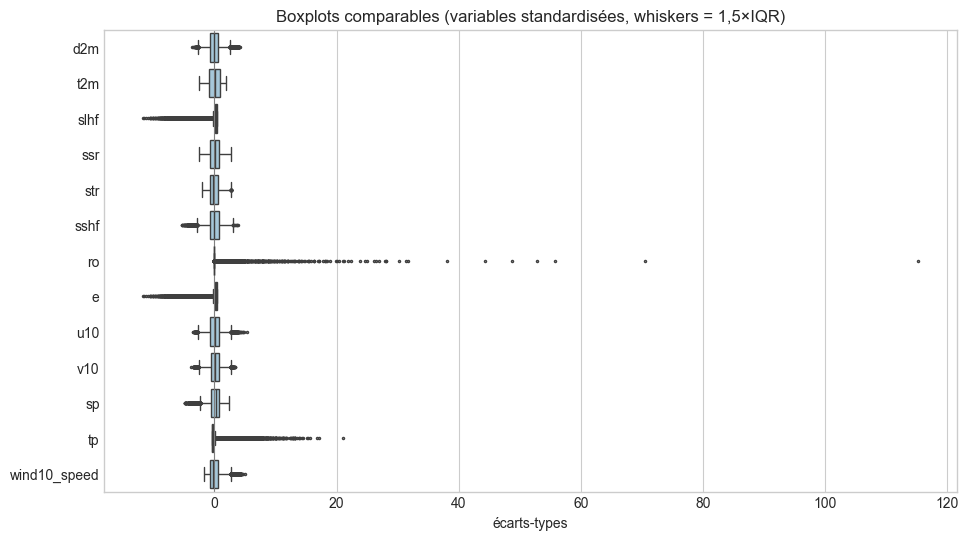

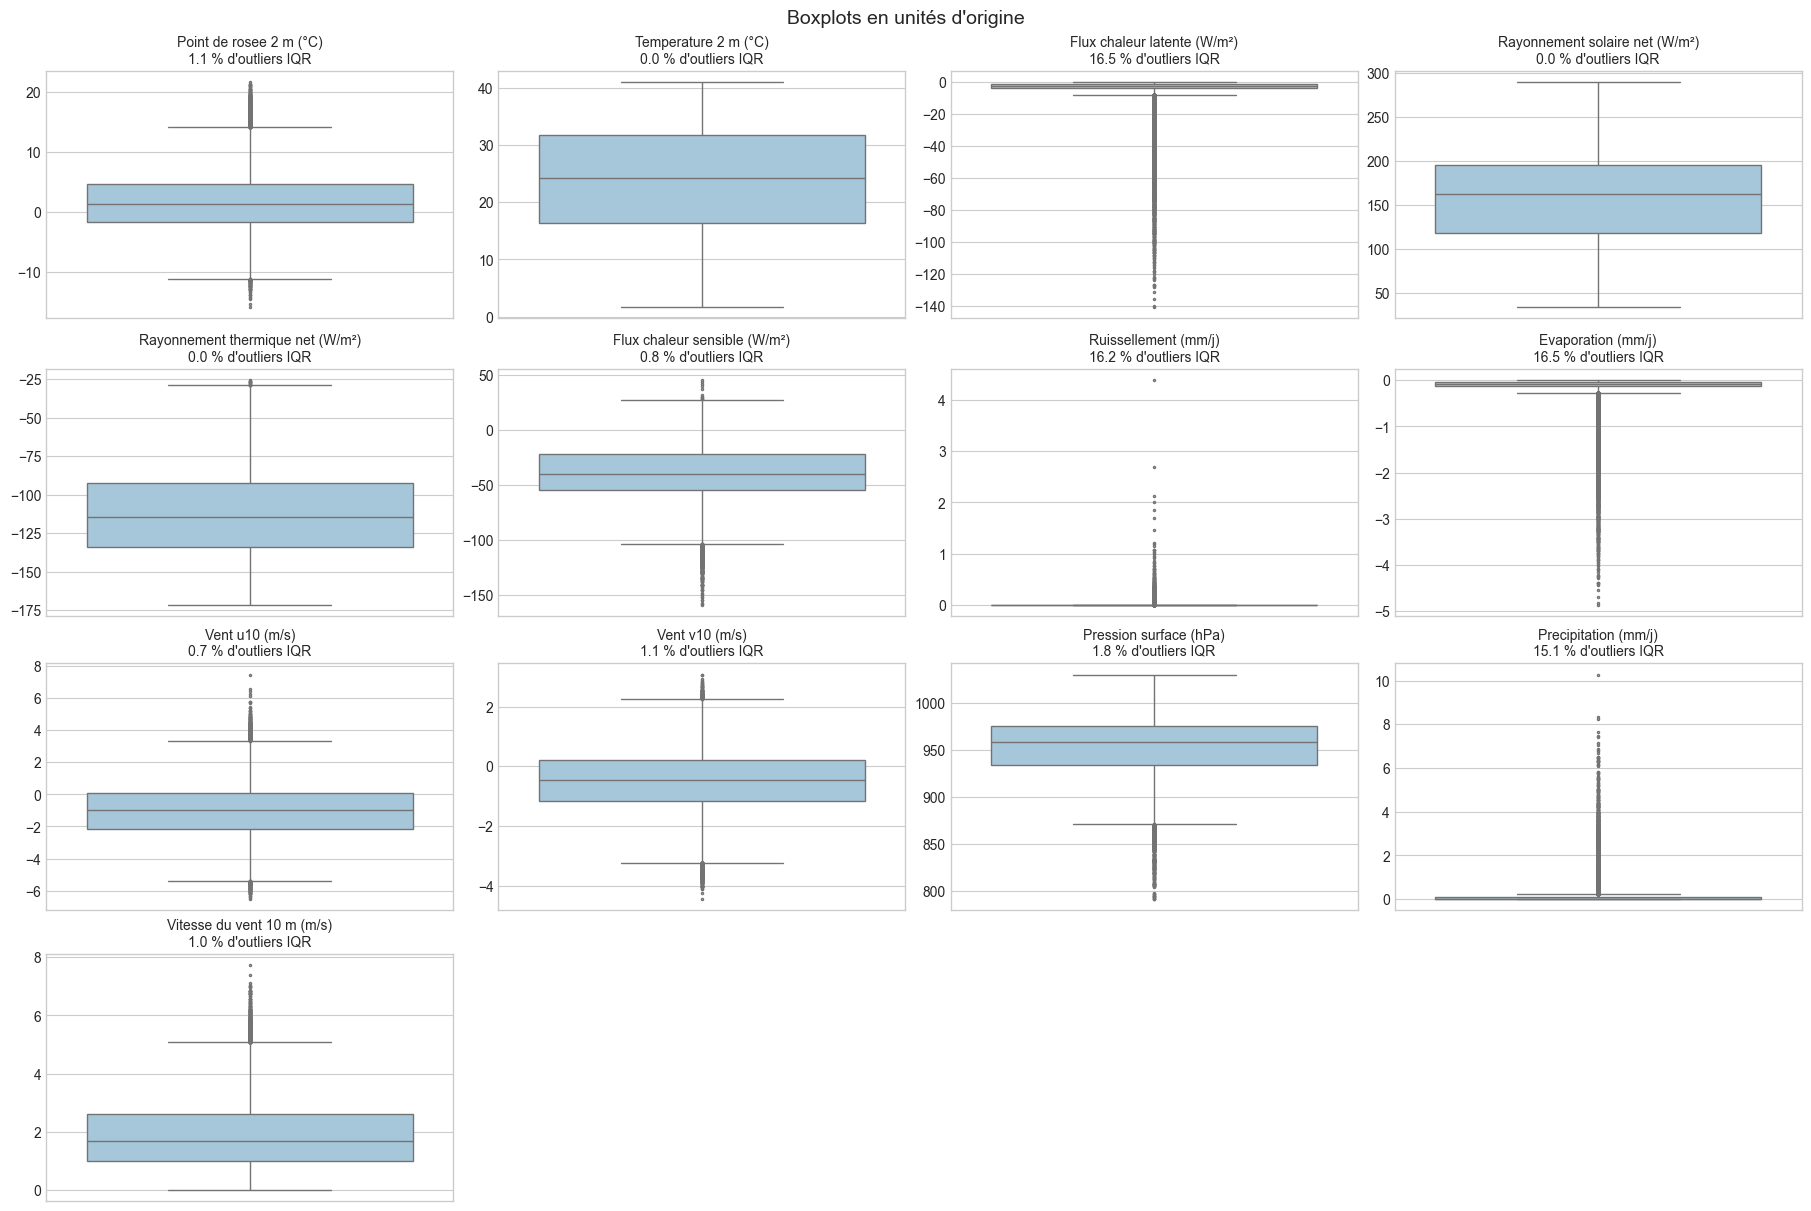

In [11]:
Z = (SAMPLE[ALL] - df[ALL].mean()) / df[ALL].std()
plt.figure(figsize=(11, 6))
sns.boxplot(data=Z, orient="h", color="#9ecae1", fliersize=1.5, whis=1.5)
plt.axvline(0, color="grey", lw=.8); plt.title("Boxplots comparables (variables standardisées, whiskers = 1,5×IQR)")
plt.xlabel("écarts-types"); plt.show()

fig, axes = plt.subplots(4, 4, figsize=(18, 12), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    sns.boxplot(y=SAMPLE[v], ax=ax, color="#9ecae1", whis=1.5, fliersize=1.5)
    ax.set_title(f"{LABELS[v]}\n{out_grid.loc[v,'% IQR']:.1f} % d'outliers IQR", fontsize=10); ax.set_ylabel("")
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Boxplots en unités d'origine", fontsize=14); plt.show()

## 3. Séries temporelles, **variation mensuelle** et cohérence entre années

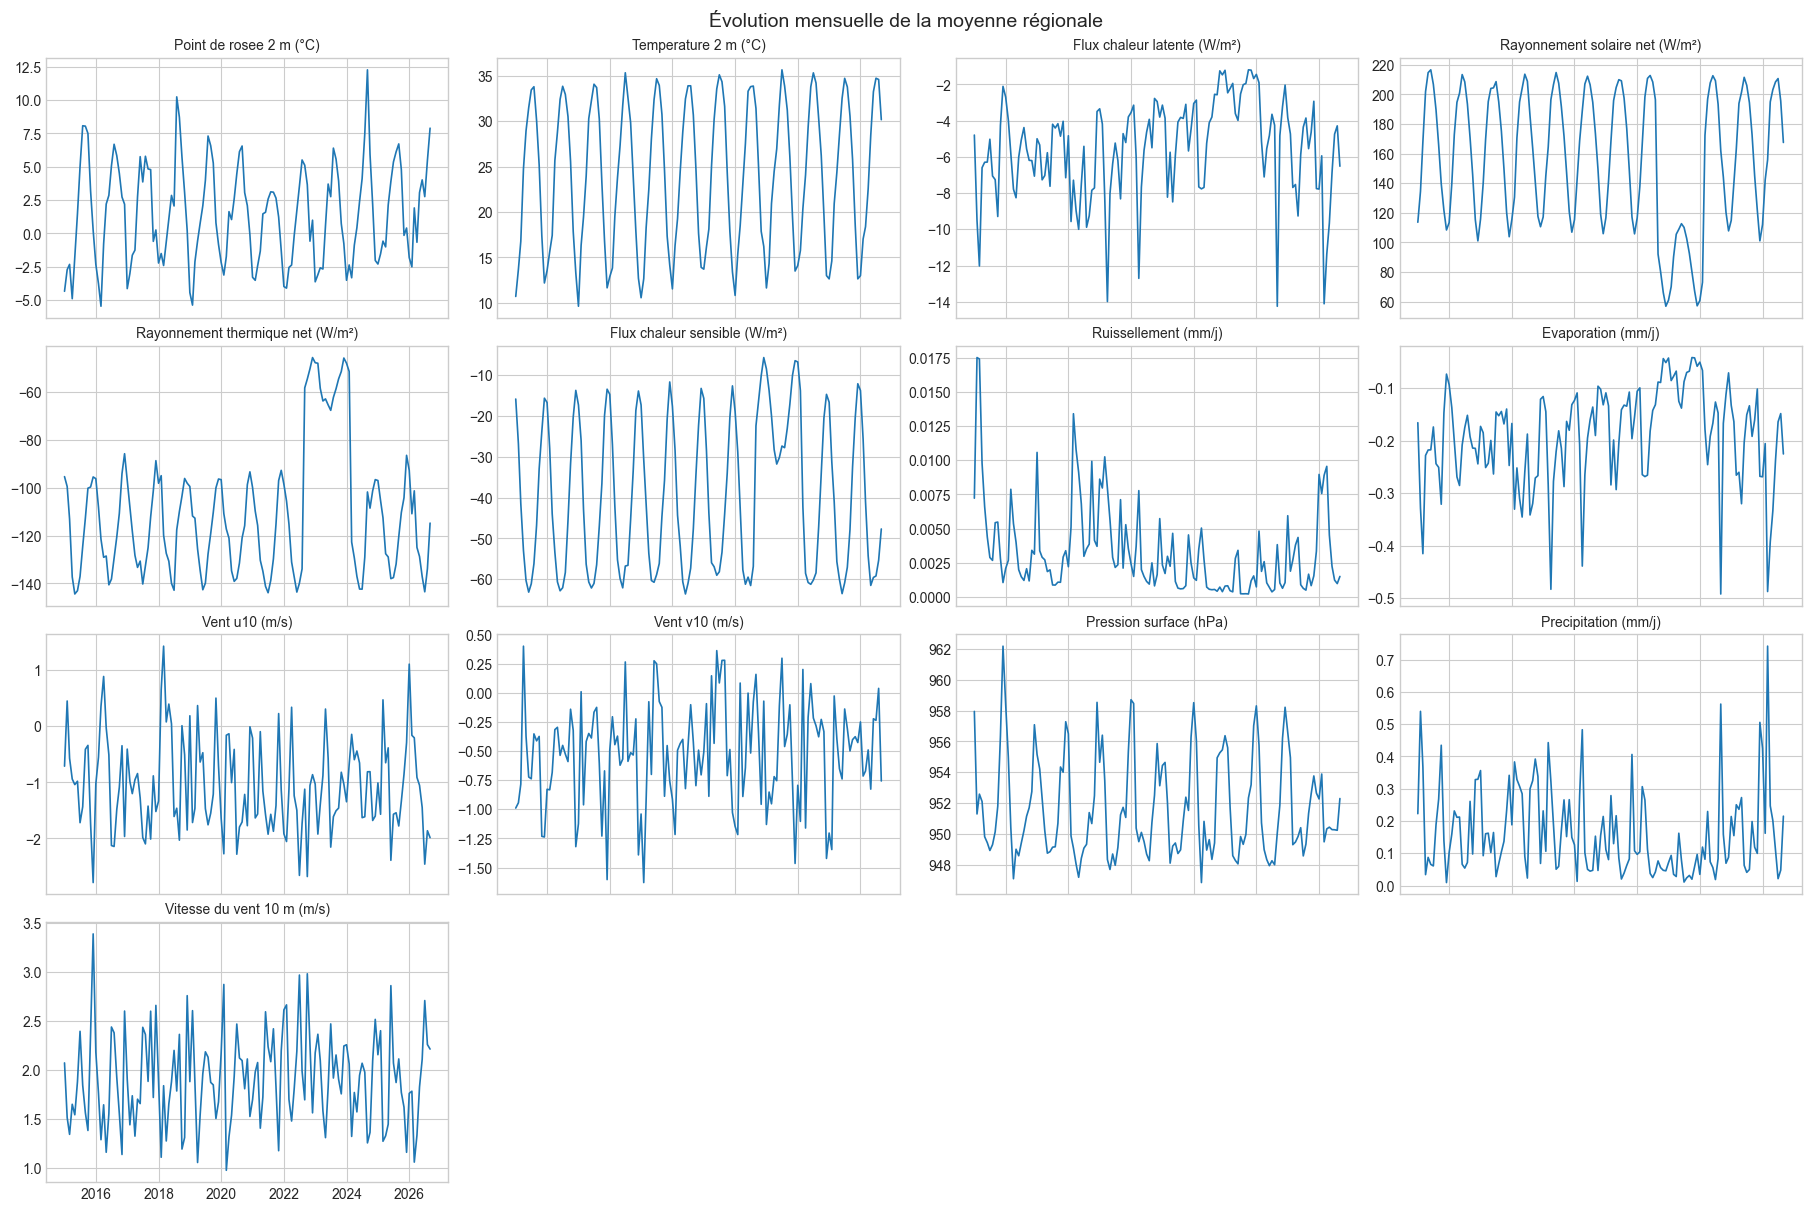

In [20]:
fig, axes = plt.subplots(4, 4, figsize=(18, 12), constrained_layout=True, sharex=True)
for ax, v in zip(axes.flat, ALL):
    ax.plot(regional.index, regional[v], lw=1.2)
    ax.set_title(LABELS[v], fontsize=10)
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Évolution mensuelle de la moyenne régionale", fontsize=14); plt.show()

**Q-Q plot 2022 vs 2024** (Cours 03 : « montrer un décalage d'une distribution à l'autre »). On compare les quantiles de la variable sur toutes les cellules en 2022 et en 2024 ; si les deux années sont cohérentes les points suivent la droite y = x.

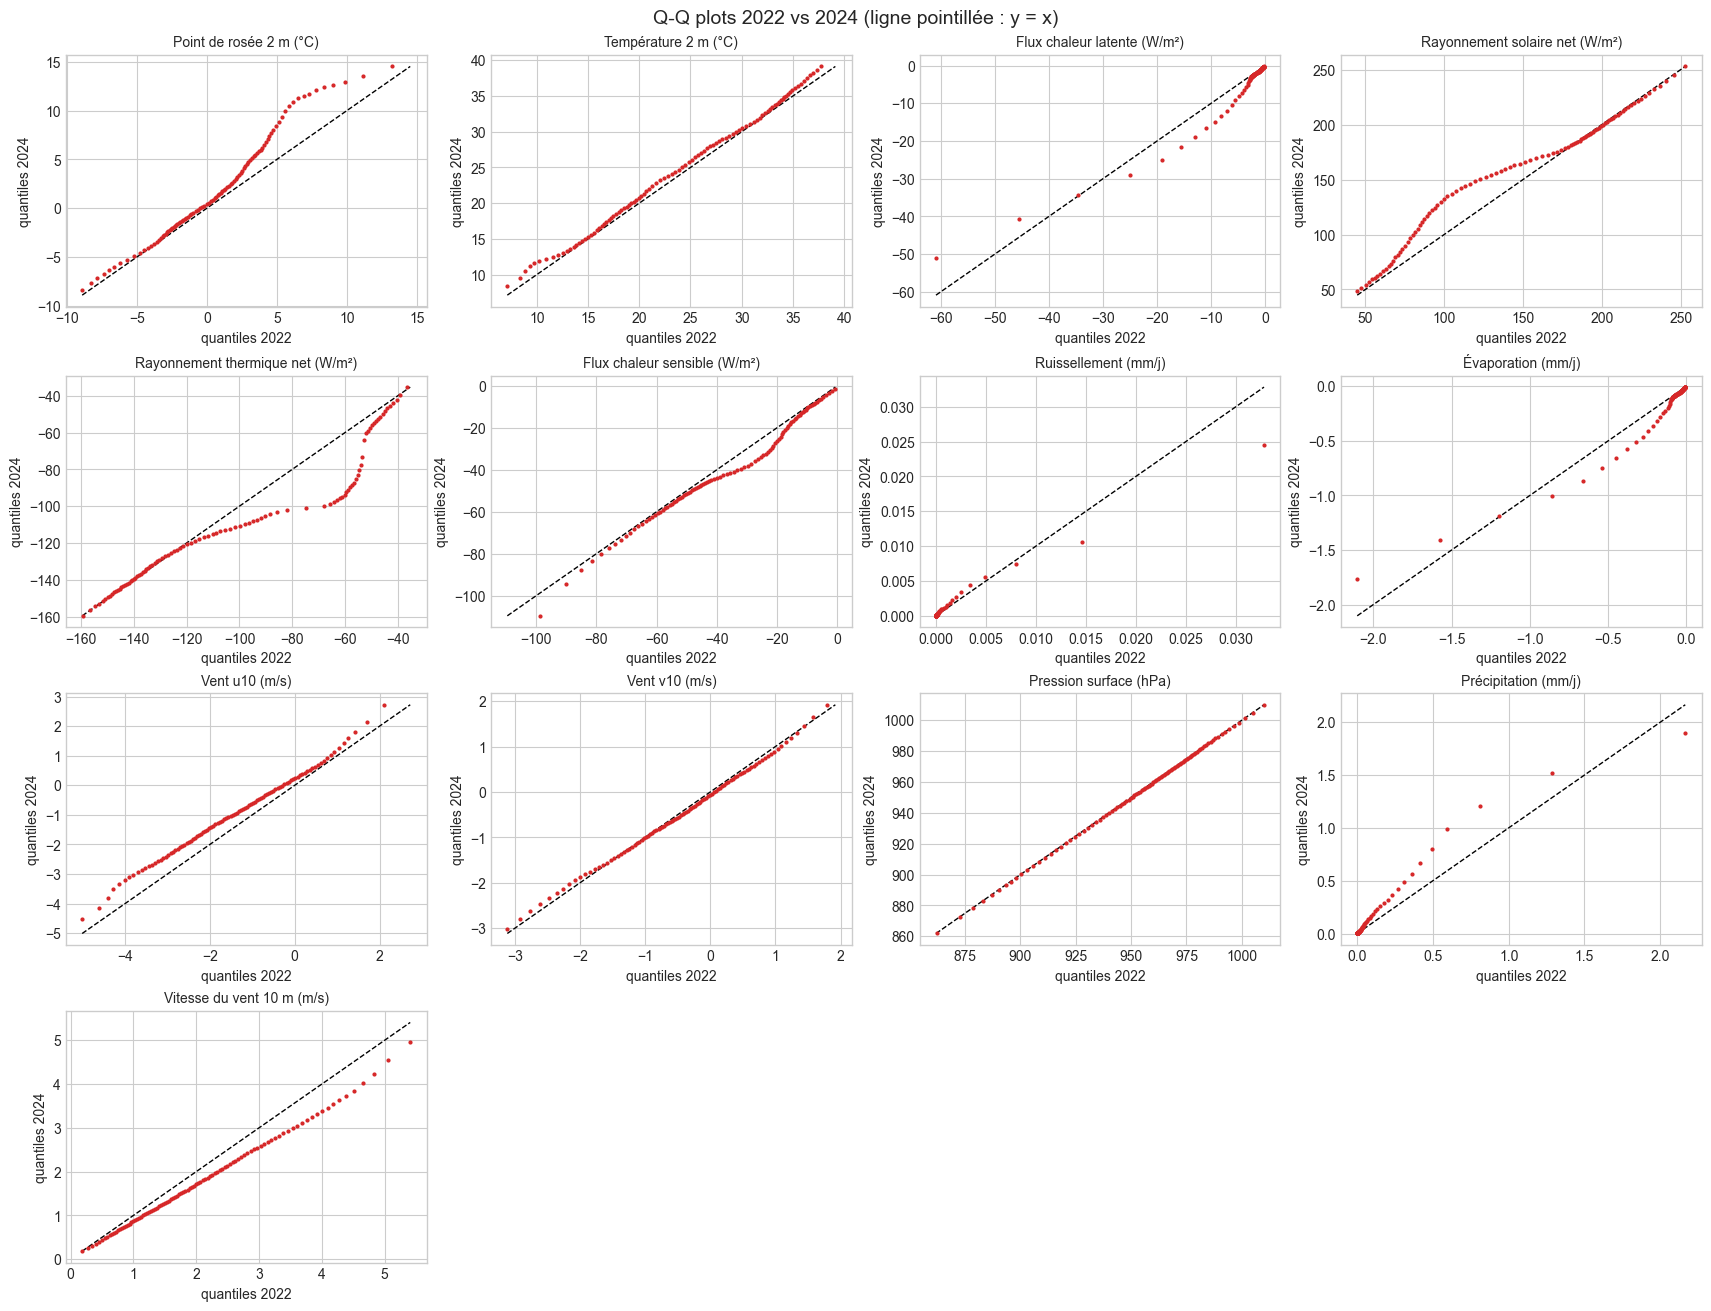

In [ ]:
qs = np.linspace(0.01, 0.99, 99)
fig, axes = plt.subplots(4, 4, figsize=(17, 13), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    a = df.loc[df["year"] == 2022, v].dropna(); b = df.loc[df["year"] == 2024, v].dropna()
    qa, qb = np.quantile(a, qs), np.quantile(b, qs)
    lim = [min(qa.min(), qb.min()), max(qa.max(), qb.max())]
    ax.plot(lim, lim, "k--", lw=1); ax.plot(qa, qb, ".", ms=4, color="tab:red")
    ax.set_title(LABELS[v], fontsize=10); ax.set_xlabel("quantiles 2022"); ax.set_ylabel("quantiles 2024")
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Q-Q plots 2022 vs 2024 (ligne pointillée : y = x)", fontsize=14); plt.show()

## 4. Analyse **bivariée** (Cours 03 : tableau des techniques selon le type de variables)

### 4.1 Numérique – Numérique : scatter plot, Pearson et Spearman (vs `t2m` et vs `t2m(t+1)`)
Règle du cours : **Pearson** si les deux variables sont normales et la relation linéaire ; **Spearman** (corrélation de rangs) si distributions non normales, outliers, ou relation monotone non linéaire.

In [ ]:
others = [v for v in ALL if v != "t2m"]
d = df.dropna(subset=["t2m_next"])
rk, rkd = df[ALL].rank(), d[ALL + ["t2m_next"]].rank()      
biv = pd.DataFrame({
    "Pearson t2m(t)":    df[others].corrwith(df["t2m"]),
    "Spearman t2m(t)":   rk[others].corrwith(rk["t2m"]),
    "Pearson t2m(t+1)":  d[others].corrwith(d["t2m_next"]),
    "Spearman t2m(t+1)": rkd[others].corrwith(rkd["t2m_next"])})
biv["|Pearson−Spearman| (t)"] = (biv["Pearson t2m(t)"] - biv["Spearman t2m(t)"]).abs()
display(biv.round(2))

,Pearson t2m(t),Spearman t2m(t),Pearson t2m(t+1),Spearman t2m(t+1),|Pearson−Spearman| (t)
d2m,0.34,0.38,0.10,0.11,0.03
slhf,0.23,-0.16,0.18,-0.15,0.39
ssr,0.61,0.61,0.70,0.71,0.00
str,-0.59,-0.66,-0.65,-0.72,0.06
sshf,-0.57,-0.60,-0.65,-0.69,0.04
ro,-0.10,-0.19,-0.09,-0.19,0.09
e,0.23,-0.16,0.18,-0.15,0.39
u10,-0.29,-0.29,-0.20,-0.21,0.00
v10,0.12,0.11,0.07,0.06,0.01
sp,0.11,0.07,0.11,0.07,0.04


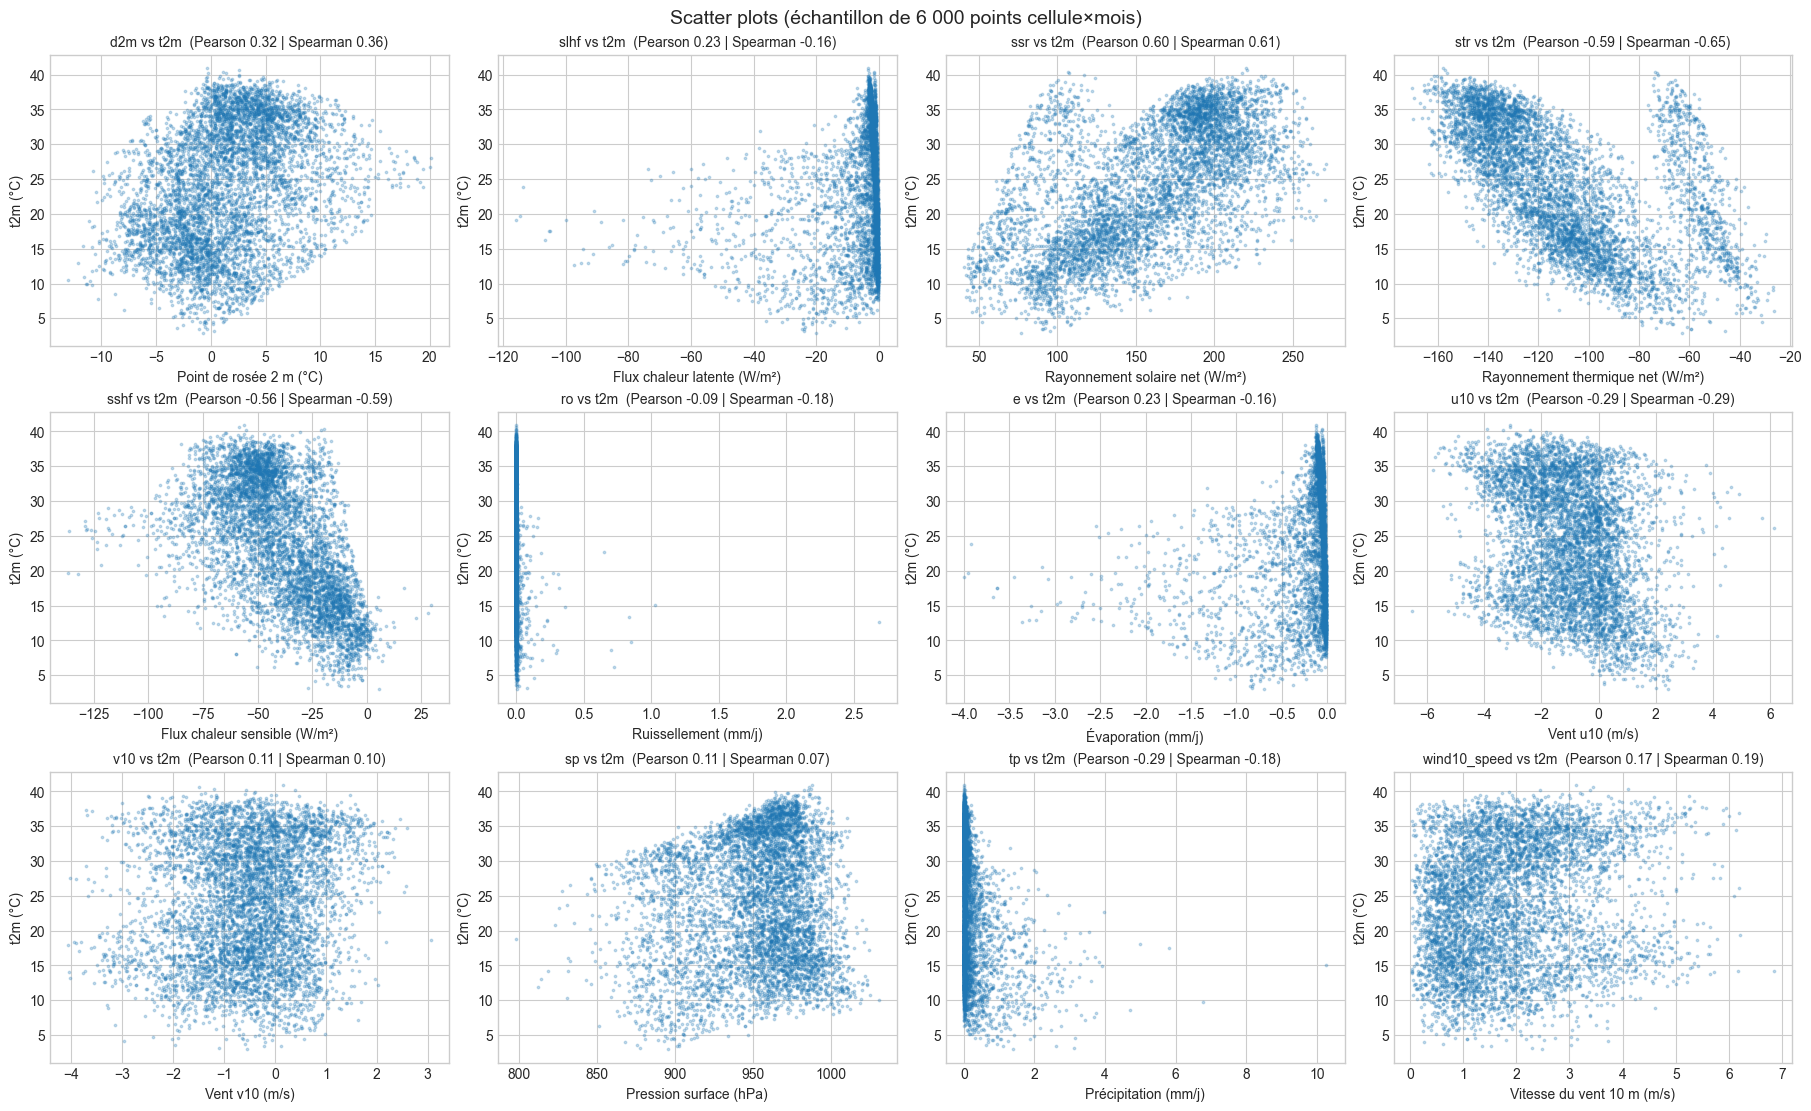

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11), constrained_layout=True)
S2 = SAMPLE.sample(6000, random_state=1)
for ax, v in zip(axes.flat, others):
    ax.scatter(S2[v], S2["t2m"], s=3, alpha=.25)
    rp = stats.pearsonr(S2[v], S2["t2m"])[0]; rs = stats.spearmanr(S2[v], S2["t2m"])[0]
    ax.set_title(f"{v} vs t2m  (Pearson {rp:.2f} | Spearman {rs:.2f})", fontsize=10)
    ax.set_xlabel(LABELS[v]); ax.set_ylabel("t2m (°C)")
fig.suptitle("Scatter plots (échantillon de 6 000 points cellule×mois)", fontsize=14); plt.show()

## 5. Analyse **multivariée** (Cours 04 : heatmap / matrice de corrélation, PCA, clustering)

### 5.1 Matrice de corrélation — choix de la bonne formule
Test de normalité de la section 2 : si **toutes** les variables étaient normales on prendrait Pearson ; sinon (asymétrie, outliers) on prend **Spearman**, comme indiqué dans le cours. On affiche les deux et leur différence.

Variables jugées normales : []
=> formule retenue : Spearman (distributions non normales / outliers)


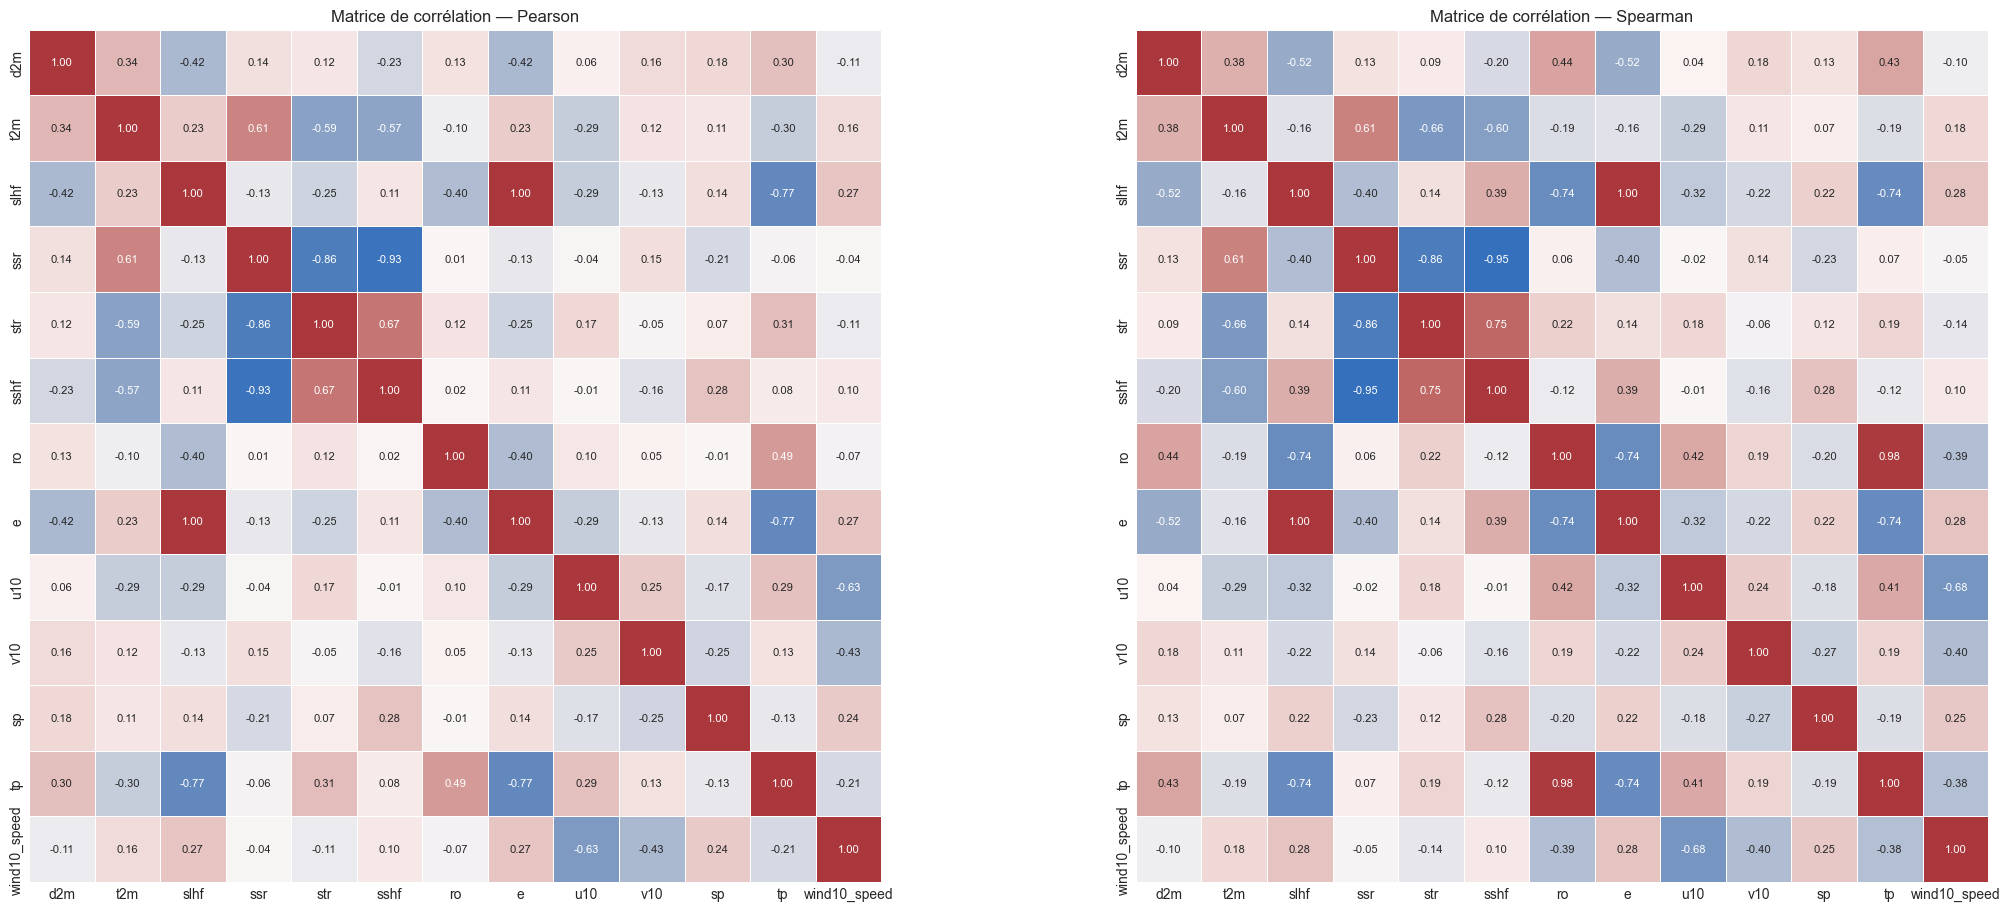

Paires |r| > 0.90 (seuil du cours — redondance) :


,var 1,var 2,r
0,slhf,e,1.000
1,ro,tp,0.980
2,ssr,sshf,-0.948


In [ ]:
use_spearman = not all(IS_NORMAL.values())
print("Variables jugées normales :", [v for v, ok in IS_NORMAL.items() if ok])
print("=> formule retenue :", "Spearman (distributions non normales / outliers)" if use_spearman else "Pearson")

corr_p = df[ALL].corr(method="pearson")
corr_s = df[ALL].rank().corr()            # Spearman = Pearson sur les rangs
main = corr_s if use_spearman else corr_p

fig, axes = plt.subplots(1, 2, figsize=(22, 9), constrained_layout=True)
for ax, m, t in [(axes[0], corr_p, "Pearson"), (axes[1], corr_s, "Spearman")]:
    sns.heatmap(m, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
                linewidths=.5, cbar=False, ax=ax, annot_kws={"size": 8}); ax.set_title(f"Matrice de corrélation — {t}")
plt.show()

pairs = (main.where(np.triu(np.ones(main.shape, bool), 1)).stack().rename("r").reset_index()
         .rename(columns={"level_0": "var 1", "level_1": "var 2"}))
HIGH = pairs[pairs["r"].abs() > 0.90].sort_values("r", key=abs, ascending=False)
print("Paires |r| > 0.90 (seuil du cours — redondance) :"); display(HIGH.round(3).reset_index(drop=True))

## 6. Dimension spatiale (grille 2×2)
> Remarque : ces moyennes temporelles incluent les 18 mois où les variables accumulées sont divisées par ≈ 2 (section 3) ; pour ces variables les cartes sont donc biaisées vers le bas (d'environ 6 % pour ssr). Elles sont recalculées sur données corrigées dans le notebook 03.

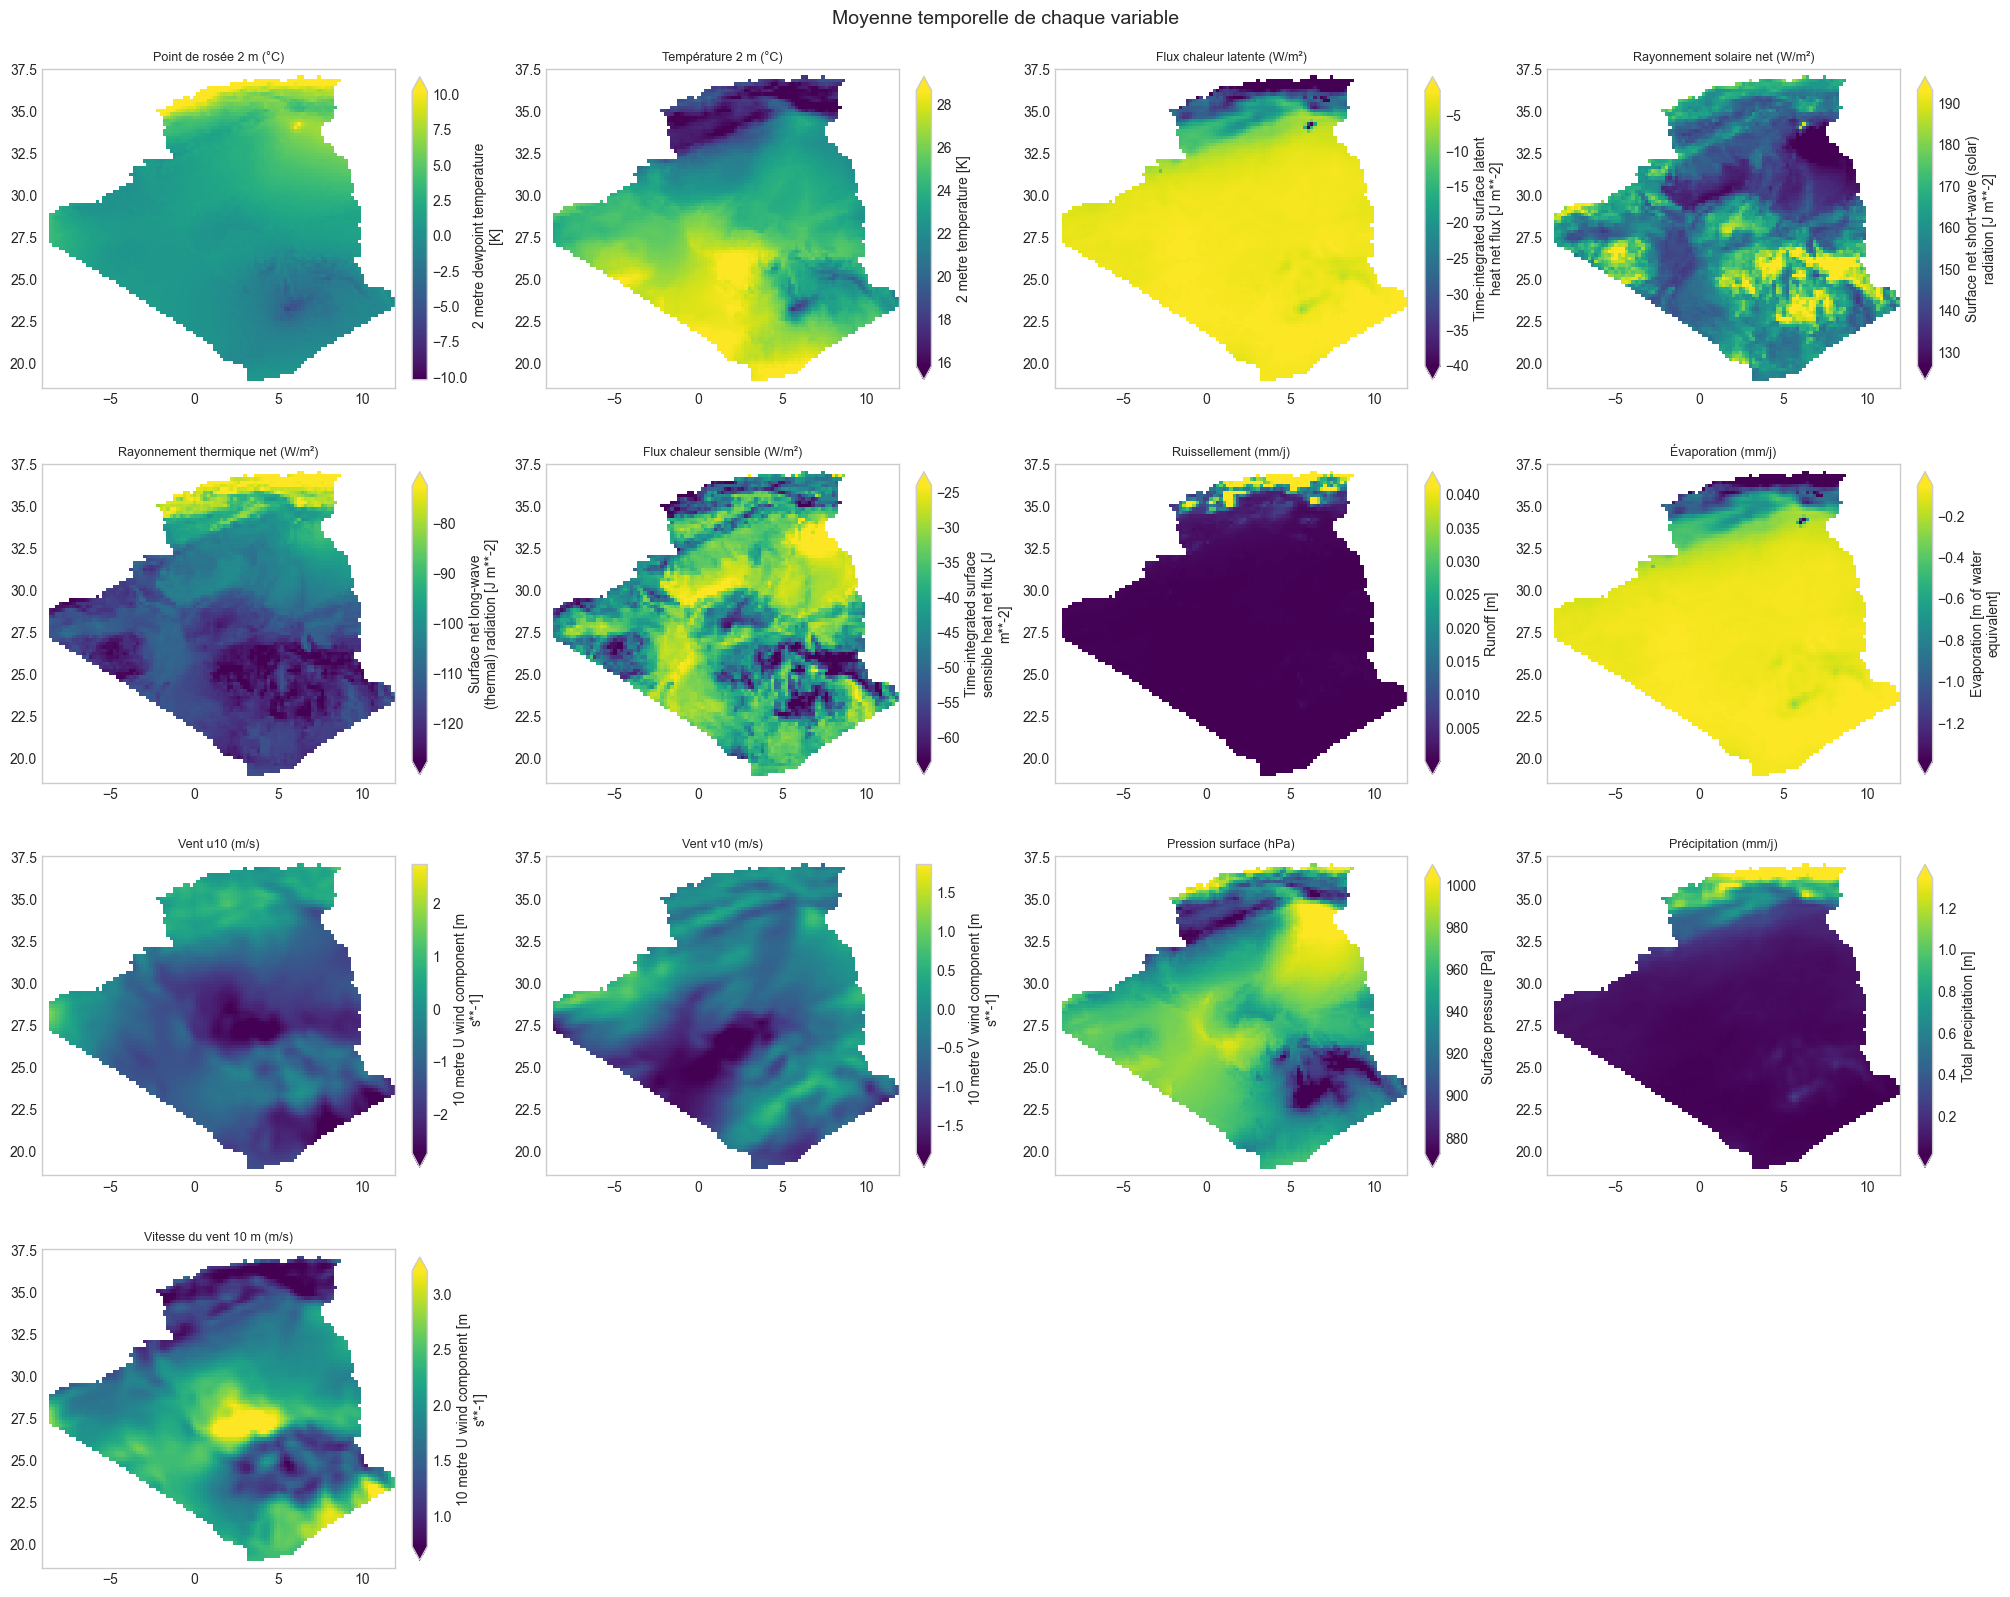

In [ ]:
tmean = conv[ALL].mean("valid_time")
fig, axes = plt.subplots(4, 4, figsize=(20, 16), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    tmean[v].plot.pcolormesh(ax=ax, x="longitude", y="latitude", cmap="viridis", robust=True, cbar_kwargs={"shrink": .8})
    ax.set_title(LABELS[v], fontsize=9); ax.set_aspect("equal"); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Moyenne temporelle de chaque variable", fontsize=14); plt.show()